In [1]:
!pip install -q shap xgboost
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
warnings.filterwarnings("ignore")

from google.colab import drive
drive.mount("/content/drive")

DRIVE = "/content/drive/MyDrive/cdss_data"
PROC  = f"{DRIVE}/processed/uci_heart"
RES   = f"{DRIVE}/results/cvd"
MODEL_DIR = f"{DRIVE}/processed/models/cvd"
SEED = 42
rng = np.random.default_rng(SEED)

Mounted at /content/drive


In [2]:
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score

# ECG side (calibrated probabilities from notebook 02)
e = np.load(f"{RES}/02_test_predictions.npz", allow_pickle=True)
CLASSES = [str(c) for c in e["classes"]]
ECG_KEY = "ecg_meta_seed42" if "ecg_meta_seed42" in e.files else [k for k in e.files if k.startswith("ecg")][0]
P_ecg, Y_ecg = e[ECG_KEY], e["Y_test"].astype(int)
NORM = CLASSES.index("NORM")
y_ecg = 1 - Y_ecg[:, NORM]               # 1 = some abnormality, 0 = normal ECG
p_ecg_abn = 1 - P_ecg[:, NORM]           # Calibrated ECG "abnormal" probability

# Clinical-values side (notebook 03)
t = np.load(f"{RES}/03_uci_test_predictions.npz", allow_pickle=True)
bundle = joblib.load(f"{MODEL_DIR}/uci_heart_models.joblib")
df = pd.read_csv(f"{PROC}/uci_heart_clean.csv")
FEATURES = bundle["features"]
cal = bundle["model"]
BEST = bundle["best"]
best_pipe = bundle["raw_models"][BEST]

X_tab = df.iloc[t["idx"]][FEATURES].reset_index(drop=True)
y_tab = t["y"].astype(int)

print("ECG model used:", ECG_KEY, "| ECG test records:", len(y_ecg), "| abnormal rate:", round(y_ecg.mean(), 3))
print("Clinical BEST model:", BEST, "| test patients:", len(y_tab), "| disease rate:", round(y_tab.mean(), 3))
print("ECG 'abnormal vs normal' AUROC:", round(roc_auc_score(y_ecg, p_ecg_abn), 3))
print("Clinical model AUROC          :", round(roc_auc_score(y_tab, cal.predict_proba(X_tab)[:, 1]), 3))

ECG model used: ecg_meta_seed42 | ECG test records: 1500 | abnormal rate: 0.557
Clinical BEST model: LogReg | test patients: 184 | disease rate: 0.554
ECG 'abnormal vs normal' AUROC: 0.936
Clinical model AUROC          : 0.903


In [3]:
N = 3000
s = rng.integers(0, 2, N)

def draw(y):
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    return np.where(s == 1, rng.choice(pos, N), rng.choice(neg, N))

ei, ti = draw(y_ecg), draw(y_tab)
pe = np.clip(p_ecg_abn[ei], 1e-4, 1 - 1e-4)

X_full = X_tab.iloc[ti].reset_index(drop=True).astype(float)
miss_frac = rng.uniform(0, 0.5, N)
X_miss = X_full.mask(rng.random(X_full.shape) < miss_frac[:, None])
n_missing = X_miss.isna().sum(axis=1).values

pt_full = np.clip(cal.predict_proba(X_full)[:, 1], 1e-4, 1 - 1e-4)
pt = np.clip(cal.predict_proba(X_miss)[:, 1], 1e-4, 1 - 1e-4)
print("simulated patients:", N, "| mean clinical inputs missing:", round(n_missing.mean(), 1), "of", len(FEATURES))

simulated patients: 3000 | mean clinical inputs missing: 4.8 of 13


In [4]:
def logit(p): return np.log(p / (1 - p))
def sigmoid(z): return 1 / (1 + np.exp(-z))

def fuse_avg(pe, pt):  return (pe + pt) / 2
def fuse_logit(pe, pt): return sigmoid(logit(pe) + logit(pt))

def auc_ci(y, p, reps=200):
    r = np.random.default_rng(0); a = []
    for _ in range(reps):
        i = r.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(y): a.append(roc_auc_score(y[i], p[i]))
    return roc_auc_score(y, p), np.percentile(a, 2.5), np.percentile(a, 97.5)

def eval_all(pe, pt, y):
    rows = []
    for name, p in [("ECG only", pe), ("Clinical only", pt),
                    ("Fusion: average", fuse_avg(pe, pt)), ("Fusion: log-odds sum", fuse_logit(pe, pt))]:
        a, lo, hi = auc_ci(y, p)
        pred = (p >= 0.5).astype(int)
        rows.append({"model": name, "AUROC": f"{a:.3f} ({lo:.3f} to {hi:.3f})",
                     "accuracy": round(accuracy_score(y, pred), 3), "F1": round(f1_score(y, pred), 3)})
    return pd.DataFrame(rows).set_index("model")

res_full = eval_all(pe, pt_full, s); res_miss = eval_all(pe, pt, s)
print("Complete clinical inputs:"); display(res_full)
print("Randomly missing clinical inputs (0 to 50 percent hidden):"); display(res_miss)
res_full.to_csv(f"{RES}/04_fusion_results_complete.csv"); res_miss.to_csv(f"{RES}/04_fusion_results_missing.csv")

Complete clinical inputs:


,AUROC,accuracy,F1
model,,,
ECG only,0.941 (0.933 to 0.948),0.866,0.863
Clinical only,0.898 (0.886 to 0.909),0.813,0.821
Fusion: average,0.977 (0.972 to 0.982),0.919,0.920
Fusion: log-odds sum,0.979 (0.974 to 0.983),0.919,0.920


Randomly missing clinical inputs (0 to 50 percent hidden):


,AUROC,accuracy,F1
model,,,
ECG only,0.941 (0.933 to 0.948),0.866,0.863
Clinical only,0.827 (0.810 to 0.842),0.723,0.763
Fusion: average,0.963 (0.957 to 0.969),0.879,0.886
Fusion: log-odds sum,0.967 (0.962 to 0.972),0.879,0.886


In [5]:
def conflict_flag(pe, pt, margin=0.1):
    return ((pe >= .5 + margin) & (pt <= .5 - margin)) | ((pt >= .5 + margin) & (pe <= .5 - margin))

pf = fuse_logit(pe, pt)
cf = conflict_flag(pe, pt)
rows = []
for name, m in [("agree / no conflict", ~cf), ("CONFLICT", cf)]:
    rows.append({"group": name, "n": int(m.sum()), "share": f"{m.mean()*100:.1f}%",
                 "fused accuracy": round(accuracy_score(s[m], (pf[m] >= .5).astype(int)), 3),
                 "ECG accuracy": round(accuracy_score(s[m], (pe[m] >= .5).astype(int)), 3),
                 "clinical accuracy": round(accuracy_score(s[m], (pt[m] >= .5).astype(int)), 3)})
conf_tab = pd.DataFrame(rows).set_index("group")
display(conf_tab); conf_tab.to_csv(f"{RES}/04_conflict_detection.csv")

,n,share,fused accuracy,ECG accuracy,clinical accuracy
group,,,,,
agree / no conflict,2292,76.4%,0.927,0.910,0.860
CONFLICT,708,23.6%,0.722,0.722,0.278


In [6]:
W_DIS, W_MISS, W_UNC = 0.4, 0.3, 0.3

def reliability(pe, pt, n_missing, n_features=len(FEATURES)):
    pf = fuse_logit(pe, pt)
    d = np.abs(pe - pt); m = n_missing / n_features; u = 1 - np.abs(2 * pf - 1)
    r = np.clip(1 - (W_DIS * d + W_MISS * m + W_UNC * u), 0, 1)
    return r, d, m, u

# Standardized labels matching Synopsis & 4-Week Plan: High, Moderate, Low
def level(r):
    return np.where(r >= .7, "High", np.where(r >= .5, "Moderate", "Low"))

rel, d_, m_, u_ = reliability(pe, pt, n_missing)
lev = level(rel)
rows = []
for L in ["High", "Moderate", "Low"]:
    m = lev == L
    rows.append({"reliability": L, "n": int(m.sum()),
                 "fused accuracy": round(accuracy_score(s[m], (pf[m] >= .5).astype(int)), 3) if m.sum() else np.nan})
rel_tab = pd.DataFrame(rows).set_index("reliability")
display(rel_tab); rel_tab.to_csv(f"{RES}/04_reliability_levels.csv")
print("correlation between reliability and being correct:",
      round(np.corrcoef(rel, ((pf >= .5).astype(int) == s).astype(int))[0, 1], 3))

,n,fused accuracy
reliability,,
High,1747,0.969
Moderate,817,0.815
Low,436,0.638


correlation between reliability and being correct: 0.375


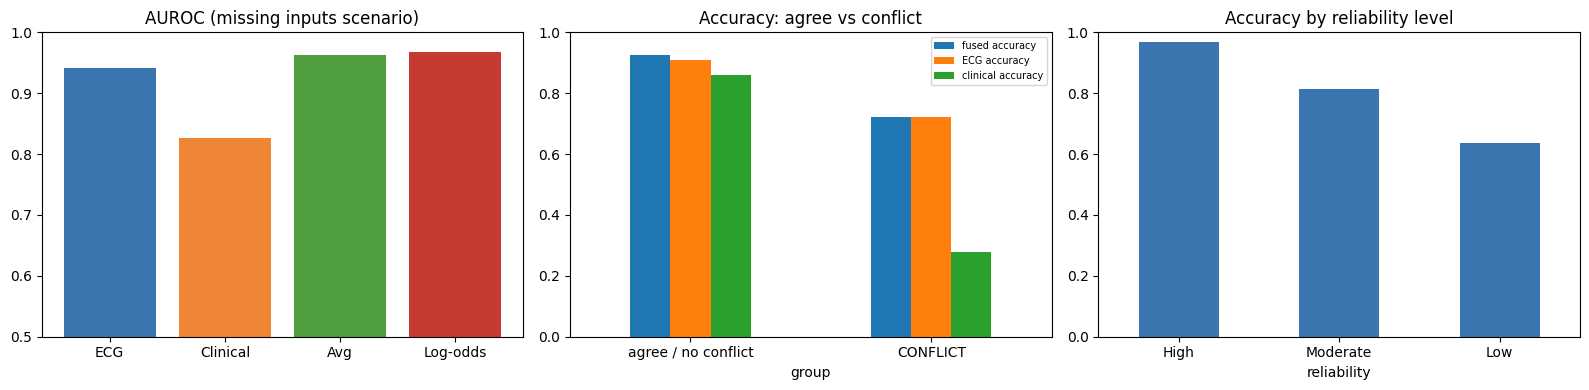

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
aucs = [float(res_miss.loc[k, "AUROC"].split()[0]) for k in res_miss.index]
ax[0].bar(range(4), aucs, color=["#3b75af", "#ef8636", "#519e3e", "#c53a32"])
ax[0].set_xticks(range(4)); ax[0].set_xticklabels(["ECG", "Clinical", "Avg", "Log-odds"])
ax[0].set_ylim(0.5, 1); ax[0].set_title("AUROC (missing inputs scenario)")
conf_tab[["fused accuracy", "ECG accuracy", "clinical accuracy"]].plot.bar(ax=ax[1], rot=0)
ax[1].set_ylim(0, 1); ax[1].set_title("Accuracy: agree vs conflict"); ax[1].legend(fontsize=7)
rel_tab["fused accuracy"].plot.bar(ax=ax[2], rot=0, color="#3b75af")
ax[2].set_ylim(0, 1); ax[2].set_title("Accuracy by reliability level")
plt.tight_layout(); plt.savefig(f"{RES}/04_fusion_conflict_reliability.png", dpi=150); plt.show()

In [8]:
MISSING_TO_TEST = {
    "chol":     "Fasting lipid profile (cholesterol)",
    "trestbps": "Resting blood pressure measurement",
    "fbs":      "Fasting blood glucose",
    "restecg":  "Resting 12-lead ECG",
    "thalach":  "Exercise stress test (heart rate response)",
    "exang":    "Exercise stress test (exercise-induced angina)",
    "oldpeak":  "Exercise stress test (ST depression)",
    "slope":    "Exercise stress test (ST slope)",
    "ca":       "Coronary imaging (CT angiography or fluoroscopy)",
    "thal":     "Nuclear stress imaging (thallium scan)",
}
ECG_CLASS_TO_TEST = {
    "MI":   "Cardiac troponin and echocardiogram",
    "STTC": "Exercise stress test or echocardiogram",
    "CD":   "Ambulatory (Holter) ECG monitoring",
    "HYP":  "Echocardiogram and blood pressure review",
}
STRESS = "Exercise stress test"

def suggest(missing, ecg_probs, conflict, p_fused, max_items=5):
    out = []
    if conflict:
        out.append({"test": "Clinician review, repeat ECG and recent labs",
                    "reason": "ECG model and clinical model disagree"})
    for c, test in ECG_CLASS_TO_TEST.items():
        if ecg_probs.get(c, 0) >= 0.5:
            out.append({"test": test, "reason": f"ECG model flags {c} (probability {ecg_probs[c]:.2f})"})
    seen_stress = False
    for col in missing:
        test = MISSING_TO_TEST.get(col)
        if not test: continue
        if test.startswith(STRESS):
            if seen_stress: continue
            seen_stress = True; test = STRESS + " (heart rate, angina, ST changes)"
        out.append({"test": test, "reason": f"{col} not available"})
    # priority: conflicts and ECG findings come first, then missing inputs; drop duplicate tests
    uniq, names = [], set()
    for o in out:
        if o["test"] not in names:
            uniq.append(o); names.add(o["test"])
    return uniq[:max_items]

In [9]:
import shap

prep, clf = best_pipe.named_steps["prep"], best_pipe.named_steps["clf"]
if BEST in ("XGBoost", "RandomForest"):
    explainer = shap.TreeExplainer(clf)
else:
    explainer = shap.LinearExplainer(clf, bundle["Xtr_background"])

FRIENDLY = {
    "age": "Age", "sex": "Sex (1 = male)", "trestbps": "Resting blood pressure", "chol": "Cholesterol",
    "fbs": "Fasting blood sugar > 120", "thalach": "Max heart rate achieved", "exang": "Exercise-induced angina",
    "oldpeak": "ST depression on exercise", "ca": "Major vessels coloured (0-3)",
    "cp_1.0": "Chest pain: typical angina", "cp_2.0": "Chest pain: atypical angina",
    "cp_3.0": "Chest pain: non-anginal", "cp_4.0": "Chest pain: asymptomatic",
    "restecg_0.0": "Resting ECG: normal", "restecg_1.0": "Resting ECG: ST-T abnormality",
    "restecg_2.0": "Resting ECG: LV hypertrophy",
    "slope_1.0": "ST slope: upsloping", "slope_2.0": "ST slope: flat", "slope_3.0": "ST slope: downsloping",
    "thal_3.0": "Thalassemia: normal", "thal_6.0": "Thalassemia: fixed defect",
    "thal_7.0": "Thalassemia: reversible defect",
}
raw_names = [n.replace("num__imp__", "").replace("num__", "").replace("cat__", "").replace("missingindicator_", "missing: ")
             for n in prep.get_feature_names_out()]
labels = [FRIENDLY.get(n, n) for n in raw_names]


def tab_explanation(row_df, top_k=4):
    xt = prep.transform(row_df[FEATURES])
    xt = xt.toarray() if hasattr(xt, "toarray") else np.asarray(xt)
    raw_sv = explainer.shap_values(xt)
    if isinstance(raw_sv, list):
        sv = raw_sv[1][0]
    elif raw_sv.ndim == 3:
        sv = raw_sv[0, :, 1]
    else:
        sv = raw_sv[0]

    out = []
    for j in np.argsort(-np.abs(sv))[:top_k]:
        n = raw_names[j]
        if n in FEATURES:
            col = n
        elif n.startswith("missing: "):
            col = n.replace("missing: ", "")
        else:
            col = n.split("_")[0]
        v = row_df[col].iloc[0] if col in FEATURES else np.nan
        out.append({"feature": labels[j], "value": None if pd.isna(v) else float(v),
                    "shap": round(float(sv[j]), 3), "direction": "raises risk" if sv[j] > 0 else "lowers risk"})
    return out


def cvd_assess(ecg_probs, row_df):
    """Returns the exact shared JSON contract expected by Member 3's FastAPI backend and React UI."""
    pe_ = float(np.clip(1 - ecg_probs["NORM"], 1e-4, 1 - 1e-4))
    pt_ = float(np.clip(cal.predict_proba(row_df[FEATURES].astype(float))[:, 1][0], 1e-4, 1 - 1e-4))
    miss = [c for c in FEATURES if pd.isna(row_df[c].iloc[0])]
    pf_ = float(fuse_logit(pe_, pt_))
    c = bool(conflict_flag(np.array([pe_]), np.array([pt_]))[0])
    r, d, m, u = reliability(np.array([pe_]), np.array([pt_]), np.array([len(miss)]))

    reasons = []
    if d[0] > 0.5: reasons.append("ECG and clinical models disagree strongly")
    elif c:        reasons.append("ECG and clinical models point in opposite directions")
    if m[0] > 0.3: reasons.append(f"{len(miss)} of {len(FEATURES)} clinical inputs are missing")
    if u[0] > 0.6: reasons.append("combined probability is close to 0.5")
    if not reasons: reasons.append("both models agree and inputs are largely complete")

    return {
        "disease": "cvd",
        "risk": round(pf_, 3),
        "reliability": str(level(r)[0]),          # "High", "Moderate", or "Low"
        "reliability_score": round(float(r[0]), 3),
        "reliability_reasons": reasons,
        "missing_inputs": miss,
        "conflicts": ([{"type": "modality_disagreement",
                        "detail": f"ECG abnormal probability {pe_:.2f} vs clinical risk {pt_:.2f}"}] if c else []),
        "suggested_investigations": suggest(miss, ecg_probs, c, pf_),
        "explanation": {
            "clinical_top_factors": tab_explanation(row_df),
            "ecg_class_probabilities": {k: round(float(v), 3) for k, v in ecg_probs.items()},
            "risk_components": {"ecg_abnormal": round(pe_, 3), "clinical": round(pt_, 3)},
        },
        "similar_cases": [],
        "disclaimer": "Decision support only. Not a diagnosis. Suggestions are rule-based and need clinician review.",
    }

In [10]:
# Three demonstration cases drawn from the simulated cohort
def case(i):
    probs = {c: float(P_ecg[ei[i], k]) for k, c in enumerate(CLASSES)}
    return cvd_assess(probs, X_miss.iloc[[i]])

true_pos_agree = np.where((s == 1) & (~cf) & (pf > .8) & (n_missing <= 1))[0][0]
conflict_i = np.where(cf)[0][0]
heavy_missing = np.where(n_missing >= 5)[0][0]
examples = {"1_agreement_high_risk": case(true_pos_agree), "2_conflict": case(conflict_i), "3_many_missing_inputs": case(heavy_missing)}
for k, v in examples.items():
    print(f"\n===== {k} (true state: {'disease' if s[[true_pos_agree, conflict_i, heavy_missing][list(examples).index(k)]] else 'no disease'}) =====")
    print(json.dumps(v, indent=2))
json.dump(examples, open(f"{RES}/04_example_api_blocks.json", "w"), indent=2)


===== 1_agreement_high_risk (true state: disease) =====
{
  "disease": "cvd",
  "risk": 1.0,
  "reliability": "High",
  "reliability_score": 0.976,
  "reliability_reasons": [
    "both models agree and inputs are largely complete"
  ],
  "missing_inputs": [
    "fbs"
  ],
  "conflicts": [],
  "suggested_investigations": [
    {
      "test": "Cardiac troponin and echocardiogram",
      "reason": "ECG model flags MI (probability 0.59)"
    },
    {
      "test": "Exercise stress test or echocardiogram",
      "reason": "ECG model flags STTC (probability 0.58)"
    },
    {
      "test": "Ambulatory (Holter) ECG monitoring",
      "reason": "ECG model flags CD (probability 0.73)"
    },
    {
      "test": "Echocardiogram and blood pressure review",
      "reason": "ECG model flags HYP (probability 0.54)"
    },
    {
      "test": "Fasting blood glucose",
      "reason": "fbs not available"
    }
  ],
  "explanation": {
    "clinical_top_factors": [
      {
        "feature": "Major ve